# 02 · IPQC stress test: where does the policy stop being safe?

We inject three physical failure modes into the trained Reacher policy and measure the damage:

| Stress | What it simulates | Wrapper |
|---|---|---|
| Observation latency | slow / delayed sensors | `ObservationLatency` |
| Actuator deadband | static friction: tiny commands do nothing | `ActuatorDeadband` |
| Motor degradation | worn motors deliver a fraction of the commanded torque | `MotorDegradation` |

Returns are negative, so each level gets a **retention score** `(R - R_random) / (R_nominal - R_random)`: 1.0 = as good as the healthy robot, 0.0 = no better than random. The **safety boundary** is the most severe level reached before the score first drops below 0.9.

Run `01_train_td3.ipynb` first (same `DFC_QUICK` setting).

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "envs" / "stress_wrappers.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

QUICK = os.environ.get("DFC_QUICK", "0") == "1"  # DFC_QUICK=1 -> tiny budgets, for smoke-testing only
PLOTS = ROOT / "plots" / ("quick" if QUICK else "")
PLOTS.mkdir(parents=True, exist_ok=True)

print("project root :", ROOT.name)
print("CUDA         :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available (cpu only)")
print("quick mode   :", QUICK)

project root : deep-feedback-control
CUDA         : NVIDIA GeForce RTX 3070 Ti Laptop GPU
quick mode   : False


In [2]:
from IPython.display import Image, display

from scripts.train import load_config
from scripts.evaluate_ipqc import (
    STRESS_FILE, describe_boundary, load_policy, run_ipqc_sweep, save_report, summarize,
)

cfg = load_config()
model = load_policy("models/reacher_td3_quick" if QUICK else cfg["model_path"])  # inference runs on CPU
threshold = cfg["ipqc"]["retention_threshold"]
print("stress levels:", {k: v for k, v in cfg["ipqc"].items() if k in ("degradation", "latency_steps", "deadband")})

stress levels: {'degradation': [1.0, 0.8, 0.6, 0.4, 0.2], 'latency_steps': [0, 1, 2, 3, 4, 5], 'deadband': [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]}


## Run the sweep

In [3]:
EPISODES, SEEDS = (3, [0]) if QUICK else (None, None)  # None -> values from the config file
raw = run_ipqc_sweep(model, cfg, episodes_per_seed=EPISODES, seeds=SEEDS)
summary = summarize(raw)
summary

site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


,stress_type,level,order,mean_return,std_return,n_episodes,score
0,deadband,0.00,0,-3.822829,1.558391,60,1.000000
1,deadband,0.05,1,-3.929624,1.542868,60,0.997298
2,deadband,0.10,2,-4.337780,1.550125,60,0.986971
3,deadband,0.20,3,-5.788846,2.818885,60,0.950258
4,deadband,0.30,4,-7.974571,3.071808,60,0.894958
5,deadband,0.50,5,-11.120204,4.829692,60,0.815372
6,degradation,1.00,0,-3.822829,1.558391,60,1.000000
7,degradation,0.80,1,-3.893887,1.566909,60,0.998202
8,degradation,0.60,2,-4.115375,1.638966,60,0.992598
9,degradation,0.40,3,-4.655695,1.848074,60,0.978928


## Safety boundaries and plots

degradation: policy keeps >= 90% retention at every level tested (up to 0.2); the boundary was not reached.
latency: safe up to 3.0; retention drops below 90% at 4.0.
deadband: safe up to 0.2; retention drops below 90% at 0.3.


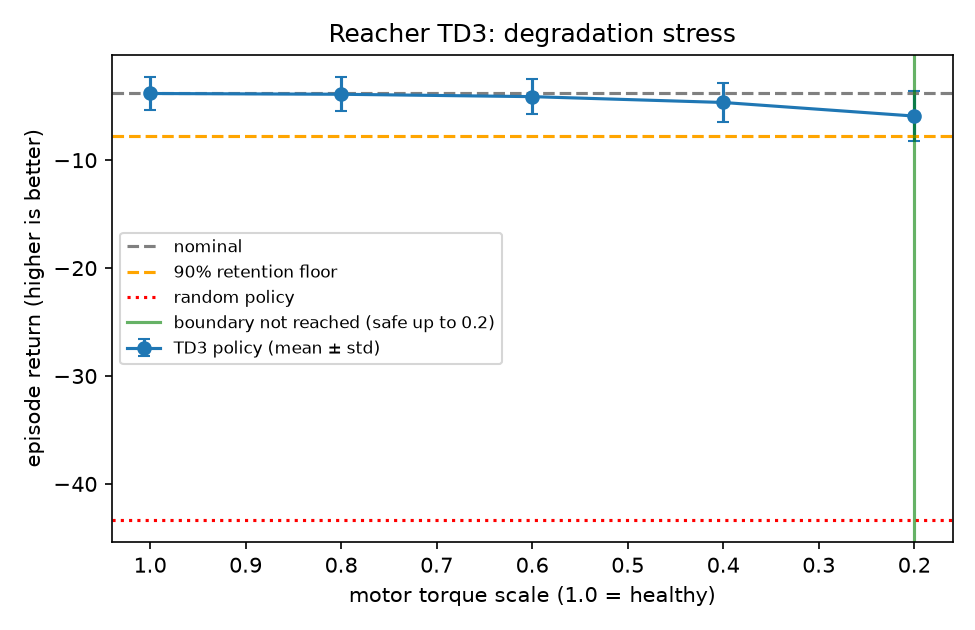

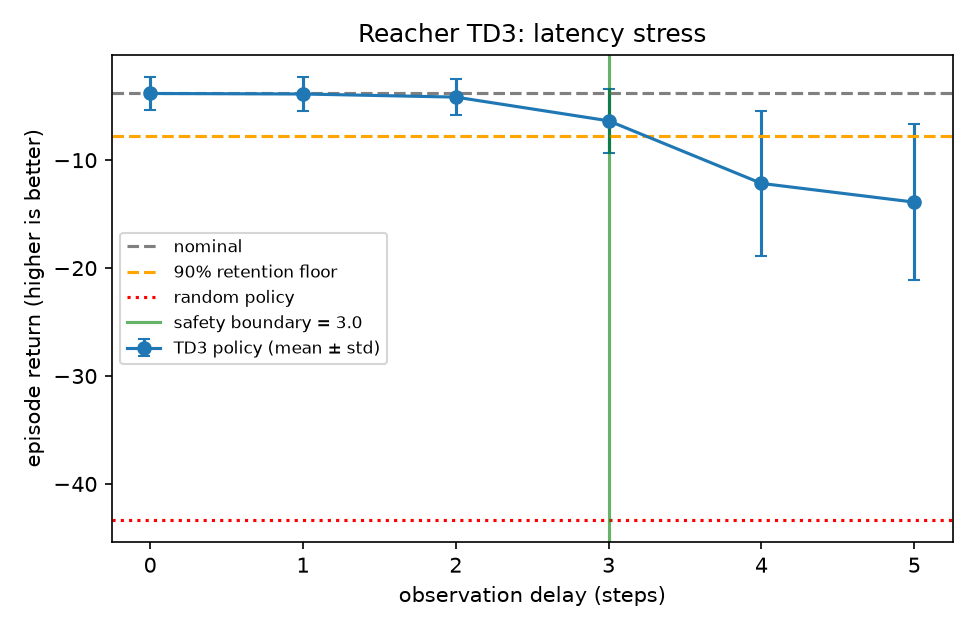

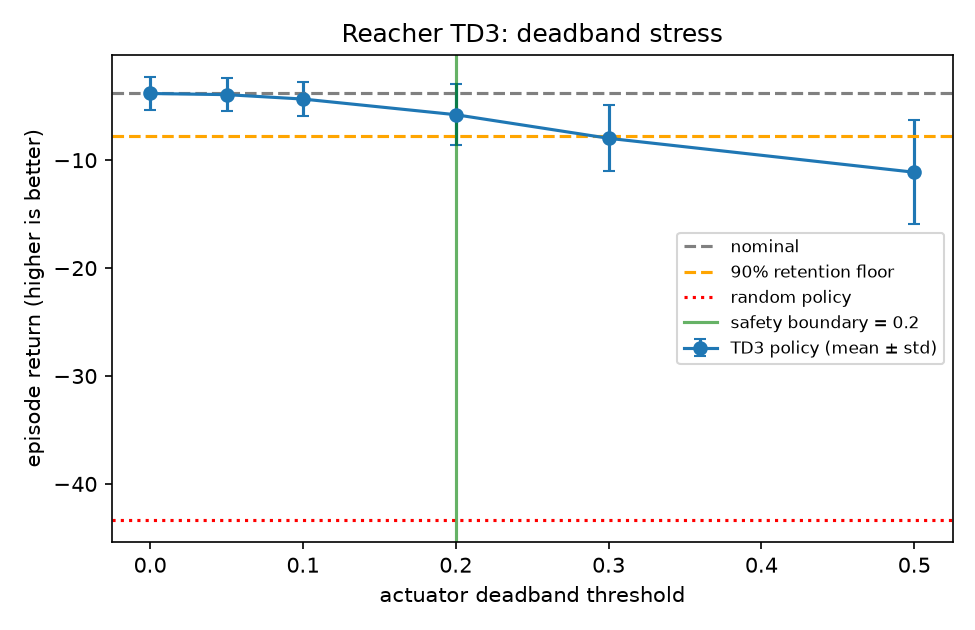

In [4]:
boundaries = save_report(summary, PLOTS, threshold)
for stress_type, boundary in boundaries.items():
    print(describe_boundary(stress_type, boundary, threshold))

for filename in STRESS_FILE.values():
    display(Image(filename=PLOTS / filename))

## Reading the plots
Each plot shows mean episode return (± std over episodes and seeds) as the stress grows. The orange line is the 90% retention floor, the red dotted line is a random policy, and the green vertical line marks the safety boundary printed above. A policy that tolerates a failure mode keeps its curve above the orange line for longer.